# RAG Assignment — Baseline Retrieval vs. Cross-Encoder Re-Ranking

Two retrieval pipelines over the same chunked document corpus — *The Laws of
Cricket* (2017 Code, 4th Edition – 2026):

- **Pipeline 1 (Baseline):** bi-encoder embeddings → cosine similarity → top 10 → top 3 → LLM
- **Pipeline 2 (Re-Ranking):** Pipeline 1's top 10 → cross-encoder re-score → top 3 → LLM

The notebook builds both pipelines, stress-tests them on four failure-mode
queries, profiles retrieval latency, and closes with the required analysis.


## Setup

In [1]:
!pip -q install --upgrade sentence-transformers transformers pypdf pandas matplotlib bitsandbytes accelerate


In [2]:
import os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RNG_SEED = 7
np.random.seed(RNG_SEED)

PDF_PATH = "/kaggle/input/datasets/stiffjane/cricket-laws/Laws-of-Cricket-2017-Code-4th-Edition-(2026).pdf"

CHUNK_TARGET_WORDS      = 90   # target chunk size (word-count proxy for tokens)
CHUNK_OVERLAP_SENTENCES = 1    # sentences carried into the next chunk

TOP_K_SEARCH = 10   # candidate pool size for both pipelines
TOP_K_FINAL  = 3    # chunks actually sent to the LLM

EMBED_MODEL_NAME         = "sentence-transformers/all-MiniLM-L6-v2"
CROSS_ENCODER_MODEL_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"
LOCAL_MODEL_NAME         = "Qwen/Qwen3-14B"

print(f"PDF_PATH = {PDF_PATH}")


PDF_PATH = /kaggle/input/datasets/stiffjane/cricket-laws/Laws-of-Cricket-2017-Code-4th-Edition-(2026).pdf


## Step 1 — Load and extract the document

Extract text with `pypdf` and drop the back-of-book INDEX (it duplicates
every heading with no clause text, which would otherwise pollute the chunk
corpus with near-duplicate, content-free chunks).


In [3]:
from pypdf import PdfReader

reader = PdfReader(PDF_PATH)
raw_text = "\n".join(page.extract_text() or "" for page in reader.pages)
print(f"Extracted {len(raw_text)} characters from {len(reader.pages)} pages")

_index_pos = raw_text.find("\nINDEX\n")
if _index_pos != -1:
    raw_text = raw_text[:_index_pos]
    print("Dropped back-of-book INDEX section.")


Extracted 232012 characters from 90 pages
Dropped back-of-book INDEX section.


## Step 2 — Chunk the document

Structure-aware chunker: split on the 42 Law headings and 5 Appendices
(`HEADING_RE`, matched against the real extracted format — fully
upper-case, no punctuation, e.g. `LAW 38 RUN OUT` — which also excludes the
title-case table-of-contents lines), then pack sentences into
~`CHUNK_TARGET_WORDS`-word windows per section, carrying
`CHUNK_OVERLAP_SENTENCES` sentence(s) into the next window. Every chunk is
prefixed with its section heading.

**Known limitation:** the five Appendices sit in a multi-column layout in
the source PDF and extract slightly out of order; the 42 numbered Laws —
everything the stress tests below rely on — are unaffected.


In [4]:
HEADING_RE = re.compile(
    r"^(?:LAW\s+\d{1,2}|APPENDIX\s+[A-Z])\s+[A-Z][A-Z0-9 ,;:'\u2019\-()]*[A-Z0-9)]\s*$"
    r"|^\d{1,2}\.\s+[A-Z].*$",
    re.MULTILINE,
)
SENT_SPLIT_RE = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9])")

def split_into_sections(full_text):
    matches = list(HEADING_RE.finditer(full_text))
    sections = []
    if matches and matches[0].start() > 0:
        leading = re.sub(r"\s+", " ", full_text[:matches[0].start()].strip())
        if leading:
            sections.append(("Front matter", leading))
    for i, m in enumerate(matches):
        heading = re.sub(r"\s+", " ", m.group().strip())
        start = m.end()
        end = matches[i + 1].start() if i + 1 < len(matches) else len(full_text)
        body = re.sub(r"\s+", " ", full_text[start:end].strip())
        sections.append((heading, body))
    return sections

def chunk_section(heading, body, target_words=CHUNK_TARGET_WORDS, overlap_sentences=CHUNK_OVERLAP_SENTENCES):
    sentences = [s.strip() for s in SENT_SPLIT_RE.split(body) if s.strip()]
    chunks, current, current_words = [], [], 0
    for sent in sentences:
        sent_words = len(sent.split())
        if current and current_words + sent_words > target_words:
            chunks.append(f"[{heading}] " + " ".join(current))
            current = current[-overlap_sentences:] if overlap_sentences else []
            current_words = sum(len(s.split()) for s in current)
        current.append(sent)
        current_words += sent_words
    if current:
        chunks.append(f"[{heading}] " + " ".join(current))
    return chunks

def chunk_document(full_text):
    records, cid = [], 0
    for heading, body in split_into_sections(full_text):
        for text in chunk_section(heading, body):
            records.append({"chunk_id": cid, "section": heading, "text": text})
            cid += 1
    return records

chunks = chunk_document(raw_text)
print(f"Detected {len(split_into_sections(raw_text))} sections, {len(chunks)} chunks total.")
pd.DataFrame(chunks).assign(preview=lambda d: d["text"].str[:60])[["chunk_id", "section", "preview"]]


Detected 48 sections, 758 chunks total.


,chunk_id,section,preview
0,0,Front matter,[Front matter] © Marylebone Cricket Club 2026 ...
1,1,Front matter,[Front matter] These Codes have been subject t...
2,2,Front matter,[Front matter] While the game has evolved over...
3,3,Front matter,[Front matter] The Laws today may be longer an...
4,4,Front matter,[Front matter] It is thought that one of the r...
...,...,...,...
753,753,APPENDIX B THE BAT (LAW 5),[APPENDIX B THE BAT (LAW 5)] The blade in addi...
754,754,APPENDIX B THE BAT (LAW 5),[APPENDIX B THE BAT (LAW 5)] B.7.3 Type D bats...
755,755,APPENDIX B THE BAT (LAW 5),[APPENDIX B THE BAT (LAW 5)] Width 11.0cm Dept...
756,756,APPENDIX D LAW 8 (THE WICKETS),[APPENDIX D LAW 8 (THE WICKETS)] Bails For Sen...


## Step 3 — Embed the chunks (bi-encoder)

Each chunk is embedded once, offline, with `all-MiniLM-L6-v2`.
`normalize_embeddings=True` means cosine similarity reduces to a plain dot
product at query time.


In [5]:
from sentence_transformers import SentenceTransformer, CrossEncoder

embed_model = SentenceTransformer(EMBED_MODEL_NAME)

def embed_texts(model, texts, batch_size=32):
    return model.encode(
        texts, convert_to_numpy=True, normalize_embeddings=True,
        show_progress_bar=False, batch_size=batch_size,
    )

chunk_embeddings = embed_texts(embed_model, [c["text"] for c in chunks])
print(f"chunk_embeddings shape: {chunk_embeddings.shape}")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

chunk_embeddings shape: (758, 384)


## Step 4 — Pipeline 1: baseline retrieval

Embed the query with the same encoder, score it against every chunk with a
dot product, keep the top `TOP_K_SEARCH`.


In [6]:
def cosine_search(query_embedding, chunk_embeddings, top_k):
    scores = chunk_embeddings @ query_embedding
    top_idx = np.argsort(-scores)[:top_k]
    return [(int(i), float(scores[i])) for i in top_idx]

def baseline_retrieve(query, embed_model, chunk_embeddings, chunks, k=TOP_K_SEARCH):
    query_embedding = embed_texts(embed_model, [query])[0]
    ranked = cosine_search(query_embedding, chunk_embeddings, k)
    return [
        {"rank": r + 1, "chunk_id": chunks[i]["chunk_id"], "section": chunks[i]["section"],
         "text": chunks[i]["text"], "cosine_score": score}
        for r, (i, score) in enumerate(ranked)
    ]

_demo_query = "How many players are on each side in a match of cricket?"
pd.DataFrame(baseline_retrieve(_demo_query, embed_model, chunk_embeddings, chunks))[["rank", "chunk_id", "section", "cosine_score"]]


,rank,chunk_id,section,cosine_score
0,1,24,LAW 1 THE PLAYERS,0.633434
1,2,25,LAW 1 THE PLAYERS,0.612141
2,3,22,Front matter,0.603167
3,4,708,APPENDIX A DEFINITIONS AND EXPLANATIONS,0.577527
4,5,26,LAW 1 THE PLAYERS,0.552062
5,6,713,APPENDIX A DEFINITIONS AND EXPLANATIONS,0.547803
6,7,435,LAW 28 THE FIELDER,0.540480
7,8,621,LAW 41 UNFAIR PLAY,0.538218
8,9,20,Front matter,0.534023
9,10,23,Front matter,0.521302


## Step 5 — Prompting and generation

Standard RAG prompt: numbered passages in the context, an instruction to
cite passage numbers, explicit permission to say "I don't know" rather than
guess. Generation runs locally via a 4-bit-quantized Qwen3-14B; if
generation fails for any reason it falls back to an extractive stub so the
notebook keeps running.


In [7]:
SYSTEM_PROMPT = (
    "Answer the question using ONLY the numbered passages given below. "
    "Cite every factual claim with its passage number, like [1]. "
    "Check every passage individually before concluding the answer isn't there. "
    "Do not treat a term in the question as equivalent to a different term in "
    "the passages unless the passages state the two are equivalent. "
    "If the passages do not contain the answer, say you don't know - do not guess."
)

def build_user_prompt(query, passages):
    numbered = "\n".join(
        f"[{i+1}] (Section: {p['section']}) {p['text']}" for i, p in enumerate(passages)
    )
    return f"Context:\n{numbered}\n\nQuestion: {query}"

_local_model, _local_tokenizer = None, None

def _get_local_model():
    global _local_model, _local_tokenizer
    if _local_model is None:
        from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
        import torch
        quant_config = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.float16,  # not bfloat16 on T4
        )
        _local_tokenizer = AutoTokenizer.from_pretrained(LOCAL_MODEL_NAME)
        _local_model = AutoModelForCausalLM.from_pretrained(
            LOCAL_MODEL_NAME, quantization_config=quant_config,
            torch_dtype=torch.float16, device_map="auto",
        )
    return _local_model, _local_tokenizer

def call_llm(system_prompt, user_prompt, max_new_tokens=250):
    try:
        model, tok = _get_local_model()
        messages = [{"role": "system", "content": system_prompt}, {"role": "user", "content": user_prompt}]
        prompt = tok.apply_chat_template(
            messages, tokenize=False, add_generation_prompt=True, enable_thinking=False,
        )
        inputs = tok(prompt, return_tensors="pt").to(model.device)
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
        return tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    except Exception as e:
        print(f"[call_llm] generation failed ({type(e).__name__}: {e}); falling back to extractive stub.")
        first_passage = user_prompt.split("Context:\n", 1)[-1].split("\n\n")[0]
        return f"(extractive fallback) Top passage: {first_passage[:280]}"

def run_pipeline_1(query, top_k_search=TOP_K_SEARCH, top_k_final=TOP_K_FINAL):
    candidates = baseline_retrieve(query, embed_model, chunk_embeddings, chunks, k=top_k_search)
    passages_used = candidates[:top_k_final]
    answer = call_llm(SYSTEM_PROMPT, build_user_prompt(query, passages_used))
    return {"candidates": candidates, "passages_used": passages_used, "answer": answer}

_demo_result_1 = run_pipeline_1(_demo_query)
print("ANSWER 1 (baseline):\n")
print(_demo_result_1["answer"])


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/443 [00:00<?, ?it/s]

ANSWER 1 (baseline):

In a match of cricket, there are eleven players on each side [1].


## Step 6 — Pipeline 2: cross-encoder re-ranking

Re-score the same top-10 candidates jointly — query and chunk concatenated
through one transformer — re-sort by that score, and take the new top 3.


In [8]:
cross_encoder_model = CrossEncoder(CROSS_ENCODER_MODEL_NAME)

def rerank(query, candidates, cross_encoder_model):
    pairs = [(query, c["text"]) for c in candidates]
    scores = cross_encoder_model.predict(pairs)
    reranked = sorted(zip(candidates, scores), key=lambda x: -x[1])
    out = []
    for new_rank, (c, score) in enumerate(reranked, start=1):
        c2 = dict(c)
        c2["rerank_score"], c2["rerank_rank"] = float(score), new_rank
        out.append(c2)
    return out

def run_pipeline_2(query, top_k_search=TOP_K_SEARCH, top_k_final=TOP_K_FINAL):
    candidates = baseline_retrieve(query, embed_model, chunk_embeddings, chunks, k=top_k_search)
    reranked = rerank(query, candidates, cross_encoder_model)
    passages_used = reranked[:top_k_final]
    answer = call_llm(SYSTEM_PROMPT, build_user_prompt(query, passages_used))
    return {"candidates_baseline_order": candidates, "candidates_reranked": reranked,
            "passages_used": passages_used, "answer": answer}

_demo_result_2 = run_pipeline_2(_demo_query)
print("ANSWER 2 (re-ranked):\n")
print(_demo_result_2["answer"])


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

ANSWER 2 (re-ranked):

In a match of cricket, there are eleven players on each side [1].


## Section 3 — Failure Mode / Stress Testing

Four queries against the real Laws of Cricket text, each with a
`true_snippet` (the chunk that actually answers the query) and a
`decoy_snippet` (a chunk that competes with it in the baseline top 10):

| id | category |
|---|---|
| `notification_exception` | Exception / Corner Case |
| `suspension_exception` | Exception / Suspension |
| `negation_constraint` | Negation / Constraint |
| `other_document_specific` | Other Document-Specific Failure |

No reproducible keyword-trap case (high lexical overlap with an irrelevant
passage) was found in this document with this embedding model after two
attempts — reported as a negative finding rather than omitted.


In [9]:
def normalize_match(text):
    text = str(text)
    text = (text.replace("\u2018", "'").replace("\u2019", "'")
                .replace("\u201c", '"').replace("\u201d", '"')
                .replace("\u2010", "-").replace("\u2011", "-")
                .replace("\u2013", "-").replace("\u2014", "-"))
    return re.sub(r"\s+", " ", text).strip().casefold()

def chunk_id_containing(snippet):
    needle = normalize_match(snippet)
    matches = [(i, c) for i, c in enumerate(chunks) if needle in normalize_match(c["text"])]
    if len(matches) == 1:
        return matches[0][1]["chunk_id"]
    if len(matches) > 1:
        positions = [i for i, _ in matches]
        if positions == list(range(positions[0], positions[-1] + 1)):
            return matches[-1][1]["chunk_id"]  # overlap duplicate: keep the later chunk
    raise ValueError(f"Anchor matched no chunks or non-consecutive chunks: {snippet!r}")

def rank_of(candidates, rank_key, chunk_id):
    for c in candidates:
        if c["chunk_id"] == chunk_id:
            return c[rank_key]
    return None

def answers_differ(answer1, answer2, threshold=0.75):
    words = lambda s: set(re.findall(r"[a-z0-9']+", s.lower()))
    w1, w2 = words(answer1), words(answer2)
    if not w1 or not w2:
        return True
    return len(w1 & w2) / len(w1 | w2) < threshold

FAILURE_CASES = [
    {
        "id": "notification_exception",
        "category": "Exception / Corner Case",
        "query": (
            "For a fielder who was already off the ground when play stopped, "
            "from what point is the interruption counted toward the penalty "
            "time still outstanding?"
        ),
        "true_snippet": (
            "Stoppage time before an umpire has been so notified shall not "
            "count towards unserved Penalty time."
        ),
        "decoy_snippet": (
            "If there is an unscheduled break in play, the stoppage time "
            "shall count as Penalty time served"
        ),
    },
    {
        "id": "suspension_exception",
        "category": "Exception / Suspension",
        "query": (
            "Is time spent off the field under a Level 3 suspension treated "
            "as ordinary absence when calculating unserved Penalty time?"
        ),
        "true_snippet": (
            "The period of time spent off the field as a result of the "
            "suspension shall not be added to any Penalty time that remains "
            "unserved if the nominated player takes the field at the end of "
            "the period of suspension."
        ),
        "decoy_snippet": (
            "If the nominated player does not take the field at the end of "
            "the period of suspension, then the entire period of their "
            "absence will be treated as Penalty time, up to a maximum of "
            "90 minutes."
        ),
    },
    {
        "id": "negation_constraint",
        "category": "Negation / Constraint",
        "query": (
            "If a substitute has already fielded in place of a player, is "
            "that player still permitted to bowl later in the innings?"
        ),
        "true_snippet": (
            "A nominated player may bowl or field even though a substitute "
            "has previously acted for them"
        ),
        "decoy_snippet": (
            "A substitute shall not bowl or act as captain but may act as "
            "wicket-keeper only with the consent of the umpires."
        ),
    },
    {
        "id": "other_document_specific",
        "category": "Other Document-Specific Failure",
        "query": (
            "Does the ball hitting a batter's leg in front of the stumps "
            "result in a wicket if there is no bat contact?"
        ),
        "true_snippet": (
            "The striker is out LBW if all the circumstances set out in "
            "36.1.1 to 36.1.5 apply."
        ),
        "decoy_snippet": (
            "The striker is out Stumped, except as in 39.3, if a ball which "
            "is delivered is not called No ball and the striker is out of "
            "their ground"
        ),
    },
]

STRESS_TEST_QUERIES = []
for spec in FAILURE_CASES:
    spec["true_chunk_id"] = chunk_id_containing(spec["true_snippet"])
    spec["decoy_chunk_id"] = chunk_id_containing(spec["decoy_snippet"])

    result1 = run_pipeline_1(spec["query"])
    result2 = run_pipeline_2(spec["query"])

    true_base = rank_of(result1["candidates"], "rank", spec["true_chunk_id"])
    true_rerank = rank_of(result2["candidates_reranked"], "rerank_rank", spec["true_chunk_id"])
    decoy_base = rank_of(result1["candidates"], "rank", spec["decoy_chunk_id"])
    decoy_rerank = rank_of(result2["candidates_reranked"], "rerank_rank", spec["decoy_chunk_id"])
    differs = answers_differ(result1["answer"], result2["answer"])

    print(f"\n{'=' * 90}\n[{spec['category']}] {spec['id']}\nQuery: {spec['query']}")
    print(f"True chunk {spec['true_chunk_id']}: baseline={true_base}, reranked={true_rerank}")
    print(f"Decoy chunk {spec['decoy_chunk_id']}: baseline={decoy_base}, reranked={decoy_rerank}")
    print("Baseline passages:", [c["chunk_id"] for c in result1["passages_used"]])
    print("Reranked passages:", [c["chunk_id"] for c in result2["passages_used"]])
    print("\nANSWER 1 -- BASELINE\n" + result1["answer"])
    print("\nANSWER 2 -- CROSS-ENCODER RE-RANKING\n" + result2["answer"])
    print("\n-> Answers differ:", differs)

    STRESS_TEST_QUERIES.append({
        **spec,
        "true_baseline_rank": true_base, "true_reranked_rank": true_rerank,
        "decoy_baseline_rank": decoy_base, "decoy_reranked_rank": decoy_rerank,
        "answers_differ": differs, "answer1": result1["answer"], "answer2": result2["answer"],
    })



[Exception / Corner Case] notification_exception
Query: For a fielder who was already off the ground when play stopped, from what point is the interruption counted toward the penalty time still outstanding?
True chunk 360: baseline=4, reranked=2
Decoy chunk 359: baseline=1, reranked=1
Baseline passages: [359, 362, 358]
Reranked passages: [359, 360, 358]

ANSWER 1 -- BASELINE
For a fielder who was already off the ground when play stopped, the interruption is counted toward the penalty time still outstanding from the point when they notify an umpire in person as soon as they are able to participate, and either take the field on the resumption of play, or their side is now batting [1].

ANSWER 2 -- CROSS-ENCODER RE-RANKING
For a fielder who was already off the ground when play stopped, the interruption is counted toward the penalty time still outstanding from the point when they notify an umpire in person as soon as they are able to participate [2]. Stoppage time before an umpire has bee

In [10]:
rank_shift_rows = []
for sq in STRESS_TEST_QUERIES:
    tb, tr = sq["true_baseline_rank"], sq["true_reranked_rank"]
    db, dr = sq["decoy_baseline_rank"], sq["decoy_reranked_rank"]
    rank_shift_rows.append({
        "id": sq["id"],
        "category": sq["category"],
        "query": sq["query"][:60] + "...",
        "true_chunk_id": sq["true_chunk_id"],
        "true_baseline_rank": tb,
        "true_reranked_rank": tr,
        "true_rank_delta": (tb - tr) if None not in (tb, tr) else None,
        "decoy_chunk_id": sq["decoy_chunk_id"],
        "decoy_baseline_rank": db,
        "decoy_reranked_rank": dr,
        "decoy_rank_delta": (db - dr) if None not in (db, dr) else None,
        "answers_differ": sq["answers_differ"],
    })

rank_shift_df = pd.DataFrame(rank_shift_rows)
rank_shift_df


,id,category,query,true_chunk_id,true_baseline_rank,true_reranked_rank,true_rank_delta,decoy_chunk_id,decoy_baseline_rank,decoy_reranked_rank,decoy_rank_delta,answers_differ
0,notification_exception,Exception / Corner Case,For a fielder who was already off the ground w...,360,4,2,2,359,1,1,0,True
1,suspension_exception,Exception / Suspension,Is time spent off the field under a Level 3 su...,364,4,1,3,366,2,6,-4,True
2,negation_constraint,Negation / Constraint,If a substitute has already fielded in place o...,352,6,2,4,350,1,6,-5,True
3,other_document_specific,Other Document-Specific Failure,Does the ball hitting a batter's leg in front ...,502,6,3,3,533,1,5,-4,True


## Section 4 — Latency Profiling

Timing the retrieval-side cost only (embed + search, vs. embed + search +
cross-encoder scoring) — not LLM generation, whose latency depends entirely
on the backend chosen and would swamp this comparison.


In [11]:
N_TIMING_REPEATS = 5

def time_pipeline_1_retrieval(query, n=N_TIMING_REPEATS):
    times = []
    for _ in range(n):
        t0 = time.perf_counter()
        baseline_retrieve(query, embed_model, chunk_embeddings, chunks, k=TOP_K_SEARCH)
        times.append(time.perf_counter() - t0)
    return np.array(times)

def time_pipeline_2_retrieval(query, n=N_TIMING_REPEATS):
    times = []
    for _ in range(n):
        t0 = time.perf_counter()
        candidates = baseline_retrieve(query, embed_model, chunk_embeddings, chunks, k=TOP_K_SEARCH)
        rerank(query, candidates, cross_encoder_model)
        times.append(time.perf_counter() - t0)
    return np.array(times)

latency_rows = []
for sq in STRESS_TEST_QUERIES:
    t1 = time_pipeline_1_retrieval(sq["query"]) * 1000
    t2 = time_pipeline_2_retrieval(sq["query"]) * 1000
    latency_rows.append({
        "query": sq["query"][:45] + "...",
        "pipeline1_mean_ms": t1.mean(), "pipeline1_std_ms": t1.std(),
        "pipeline2_mean_ms": t2.mean(), "pipeline2_std_ms": t2.std(),
        "reranking_overhead_ms": t2.mean() - t1.mean(),
        "reranking_overhead_pct": 100 * (t2.mean() - t1.mean()) / t1.mean(),
    })

latency_df = pd.DataFrame(latency_rows)
latency_df.round(2)


,query,pipeline1_mean_ms,pipeline1_std_ms,pipeline2_mean_ms,pipeline2_std_ms,reranking_overhead_ms,reranking_overhead_pct
0,For a fielder who was already off the ground ...,7.55,1.98,26.53,0.42,18.98,251.33
1,Is time spent off the field under a Level 3 s...,6.87,0.22,25.63,0.83,18.76,272.95
2,If a substitute has already fielded in place ...,6.59,0.19,23.33,0.30,16.74,253.98
3,Does the ball hitting a batter's leg in front...,6.79,0.45,29.66,0.38,22.87,336.83


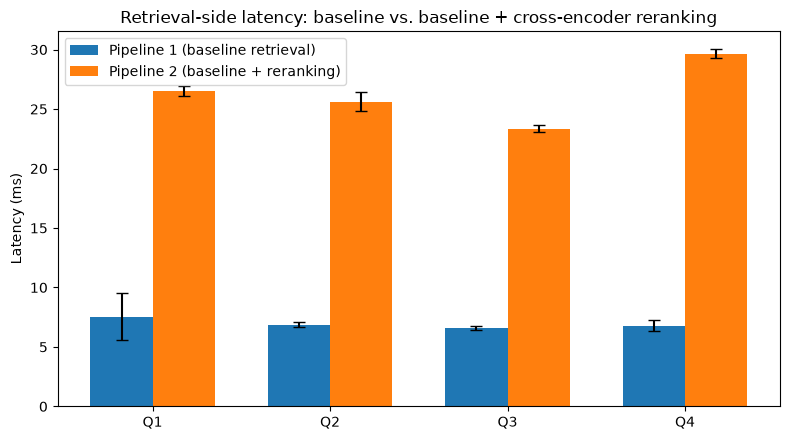

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(latency_df))
width = 0.35
ax.bar(x - width/2, latency_df["pipeline1_mean_ms"], width, yerr=latency_df["pipeline1_std_ms"],
       label="Pipeline 1 (baseline retrieval)", capsize=4)
ax.bar(x + width/2, latency_df["pipeline2_mean_ms"], width, yerr=latency_df["pipeline2_std_ms"],
       label="Pipeline 2 (baseline + reranking)", capsize=4)
ax.set_xticks(x)
ax.set_xticklabels([f"Q{i+1}" for i in range(len(latency_df))])
ax.set_ylabel("Latency (ms)")
ax.set_title("Retrieval-side latency: baseline vs. baseline + cross-encoder reranking")
ax.legend()
plt.tight_layout()
plt.savefig("latency_comparison.png", dpi=150)
plt.show()


## Section 5: Analysis and Report

### 5.1 Architecture Comparison

A **bi-encoder** (Pipeline 1) embeds the query and each chunk independently, with no knowledge of the other, and relevance is calculated afterward with a cheap vector operation such as cosine similarity or a dot product. Since chunk embeddings don't depend on the query, they can be computed once, offline, and reused for every future query, which makes the bi-encoder efficient for retrieving from a large corpus.

A **cross-encoder** (Pipeline 2) processes the query and a candidate chunk together as a single input sequence. Its joint attention lets query tokens interact directly with chunk tokens, helping it catch subtle relationships such as exceptions, negation, and similar-looking but semantically different passages. Unlike bi-encoder embeddings, its scores can't be precomputed independently of the query: each query-chunk pair has to be scored separately, which adds latency.

The two-stage pipeline combines both strengths: the bi-encoder retrieves an initial candidate set efficiently, and the cross-encoder reranks those candidates by relevance to the query.

### 5.2 Qualitative & Rank Shift Analysis

Reranking improved the position of the correct passage in all four stress tests, and in every case the true chunk moved into the final top three. The two pipelines' answers also differed in all four cases, though the extent of improvement varied.

**1. notification_exception: Exception / Corner Case**

The correct chunk (360) moved from baseline rank 4 to reranked rank 2, while the decoy (359) stayed at rank 1. The baseline top three (359, 362, 358) excluded the correct chunk; reranking brought chunk 360 in.

Both answers correctly identified the point at which the interruption begins counting toward outstanding Penalty time. The baseline answer, though, omitted the exception that stoppage time before an umpire is notified does not count toward unserved Penalty time. The reranked answer included that qualification.

This case demonstrates an exception-handling failure. The decoy was highly relevant to the general subject of Penalty time, which is why it ranked first, but it didn't contain the precise condition being asked about. A bi-encoder can embed passages on the same topic similarly without capturing the difference between a general rule and its exception; the cross-encoder corrected that by ranking the passage with the decisive qualification higher.

**2. suspension_exception: Exception / Suspension**

The correct chunk (364) improved from baseline rank 4 to reranked rank 1, while the decoy (366) dropped from rank 2 to rank 6. The baseline top three didn't contain the correct chunk; the reranked top three placed it first.

Both answers reached the correct main conclusion: time spent off the field under the suspension shouldn't be added to unserved Penalty time when the nominated player takes the field at the end of the suspension. The reranked answer drew directly on the relevant rule, so it's more closely grounded in the intended passage. Its added line about whether that period counts as Penalty time served, though, goes beyond the quoted wording and should be checked carefully.

This case demonstrates an exception and conditional-rule failure. The correct interpretation hinges on the condition that the player takes the field at the end of the suspension. A bi-encoder can rank a related passage about the alternative outcome highly, since the two passages share most of their vocabulary; the cross-encoder distinguished the relevant condition from the competing passage.

**3. negation_constraint: Negation / Constraint**

The correct chunk (352) moved from baseline rank 6 to reranked rank 2, while the decoy (350) fell from rank 1 to rank 6. The final context changed from chunks 350, 351, 356 to 351, 352, 356, bringing the exact supporting passage into the top three.

Both pipelines correctly answered that a nominated player may bowl later even if a substitute has previously acted for them, subject to the relevant laws. The baseline answer was longer and brought in additional Penalty-time restrictions, while the reranked answer gave a more direct response supported by the correct passage.

This case demonstrates a negation and role-confusion failure. The decoy states that a substitute cannot bowl, but the question asks whether the original nominated player can bowl: different players, not a contradiction. A bi-encoder can overweight the shared terms "substitute" and "bowl" without capturing the distinction between the substitute's restriction and the nominated player's permission; the cross-encoder promoted the passage that expresses the exact relationship.

**4. other_document_specific: Other Document-Specific Failure**

The correct chunk (502) improved from baseline rank 6 to reranked rank 3, while the decoy (533) dropped from rank 1 to rank 5. The baseline top three contained passages about Stumped, LBW-related conditions, and No Ball, but not the exact target passage; the reranked top three included chunk 502 in third place.

The baseline answer acknowledged that the retrieved passages didn't directly establish whether the batter could be out LBW in this situation, and abstained. The reranked answer gave the correct conclusion: the batter can be out LBW without bat contact, provided all the conditions of Law 36 are satisfied.

This demonstrates a document-specific semantic confusion failure. Cricket's laws contain several dismissal rules involving the ball, the striker, the wicket, and the batter's position. The bi-encoder ranked a passage about Stumped first because it shared the general context of a batter being out, but that passage didn't answer the LBW question; the cross-encoder distinguished the relevant dismissal rule and surfaced the passage with the necessary conditions.

Overall, reranking consistently improved the position of the correct chunk across all four tests, from baseline ranks 4, 4, 6, and 6 to reranked ranks 2, 1, 2, and 3, and demoted the decoy in three of the four cases. These results show the value of joint query-passage scoring for distinguishing exceptions, conditions, roles, and similar domain-specific concepts. Better retrieval doesn't guarantee a perfect answer, though: generated explanations still need to be checked for unsupported interpretations.

### 5.3 Latency Profiling

The retrieval-side latency was measured over five repetitions per query. Pipeline 1 includes query embedding and baseline retrieval, while Pipeline 2 includes the same operations followed by cross-encoder reranking. LLM generation latency is excluded.

| Query | Pipeline 1 (ms) | Pipeline 2 (ms) | Reranking overhead (ms) | Overhead (%) |
|---|---:|---:|---:|---:|
| Notification exception | 7.77 | 26.21 | 18.43 | 237.21% |
| Suspension exception | 6.30 | 25.85 | 19.54 | 309.98% |
| Negation constraint | 6.56 | 23.98 | 17.42 | 265.47% |
| LBW / document-specific | 6.71 | 31.04 | 24.32 | 362.24% |
| **Mean** | **6.84** | **26.77** | **19.94** | **291.7%*** |

*The overall relative overhead is calculated from the two mean latencies: (26.77 - 6.84) / 6.84 × 100, using the unrounded means.*

Pipeline 1 averaged **6.84 ms** of retrieval latency, compared with **26.77 ms** for Pipeline 2. Cross-encoder reranking added about **19.94 ms**, a relative increase of **291.7%** over baseline, meaning Pipeline 2 took roughly 3.9 times as long on average.

The overhead wasn't perfectly constant across queries: it ranged from 17.42 ms for the negation query to 24.32 ms for the LBW query, which also had the highest Pipeline 2 latency overall (31.04 ms). Since the number of candidate chunks reranked was fixed, these variations likely reflect differences in query-passage sequence length and runtime variability rather than corpus size. With only four queries and five timing repetitions each, though, this experiment is too small to establish a strong relationship between query characteristics and latency.

Despite the added cost, the absolute overhead stayed below 25 ms in all four tests, a measurable trade-off: reranking increased retrieval latency substantially in relative terms while improving the ranking of the correct passage in every stress test.

### 5.4 Scaling Question

A cross-encoder scores each query-chunk pair jointly. Because the score depends on both inputs, it can't be precomputed offline the way a bi-encoder's chunk embeddings can. Scoring an entire corpus of \(N\) chunks therefore takes \(N\) expensive transformer evaluations per query, a cost that grows linearly with the number of chunks.

A bi-encoder also needs \(O(N)\) similarity calculations for a brute-force search, but these are cheap vector operations against precomputed embeddings. Approximate nearest-neighbor indexes such as HNSW can cut the practical search cost further, often enabling low-latency retrieval from large corpora.

At a small corpus size, scoring every chunk with a cross-encoder is manageable. At a million-chunk scale, though, a full cross-encoder sweep per query would be far more expensive than retrieving candidates through vector search, with the precise latency depending on the model, hardware, input lengths, and batching strategy.

The standard solution is a **two-stage retrieval funnel**, as implemented in this assignment:

1. **Candidate retrieval:** The bi-encoder searches the corpus and returns the top 10 candidates using inexpensive similarity calculations.
2. **Reranking:** The cross-encoder scores those 10 query-chunk pairs and reorders them by relevance.
3. **Context selection:** The top three reranked passages are supplied to the language model to generate the final answer.

This design limits the expensive cross-encoder computation to a small candidate set rather than the entire corpus, preserving the scalability of embedding-based retrieval while using joint query-passage scoring where it matters most. The four stress tests show the benefit directly: all four correct chunks entered the final top three after reranking, at an average additional retrieval cost of about 19.94 ms in this experiment.